# EN3150 Assignment 03
## Resource-Constrained CNN for Fashion-MNIST

1. Import libraries
2. Load Fashion-MNIST
3. Understand the data
4. Split data into 70% train, 15% validation, 15% test
5. Preprocess the images
6. Build Model A - Standard CNN
7. Build Model B - Lightweight CNN
8. Compare trainable parameters
9. Compare optimizers
10. Train Model A and Model B
11. Plot loss curves
12. Evaluate both models
13. Compare model size, training time and accuracy
14. Fine-tune MobileNetV2
15. Fine-tune EfficientNetB0
16. Final comparison

## 1. Import Libraries

We first import the libraries needed for the project.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

## 2. Load Fashion-MNIST

Fashion-MNIST has 70,000 grayscale clothing images.

Each image is 28 x 28 pixels, so it is already smaller than the assignment limit of 64 x 64 pixels.

In [2]:
(x1, y1), (x2, y2) = keras.datasets.fashion_mnist.load_data()

# Combine the original train and test sets.
# We do this because our assignment needs a new 70/15/15 split.

images = np.concatenate((x1, x2))
labels = np.concatenate((y1, y2))

print("Images:", images.shape)
print("Labels:", labels.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Images: (70000, 28, 28)
Labels: (70000,)


## 3. Class Names

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

## 4. View Some Images

Before training, we look at a few samples from the dataset.

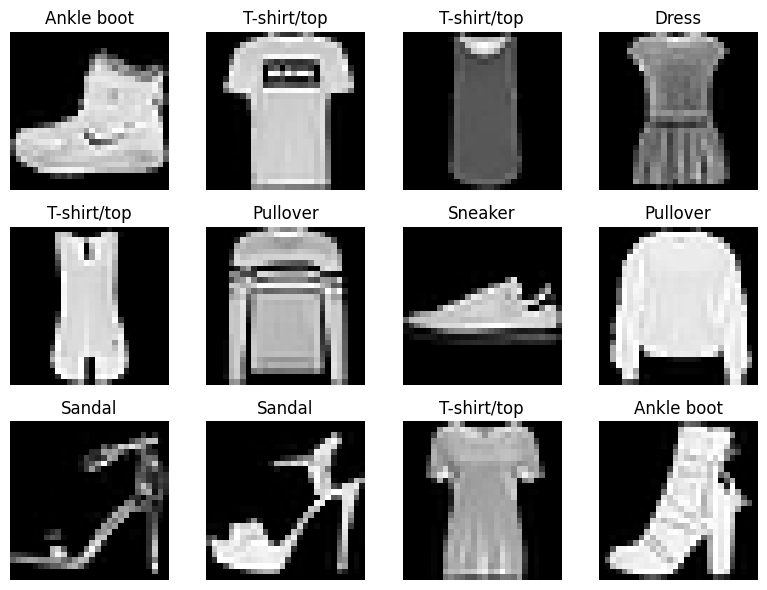

In [4]:
plt.figure(figsize=(8, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Check Class Distribution

Fashion-MNIST is a balanced dataset.  
We check how many images belong to each class.

In [5]:
counts = np.bincount(labels)

for i in range(10):
    print(i, class_names[i], ":", counts[i])

0 T-shirt/top : 7000
1 Trouser : 7000
2 Pullover : 7000
3 Dress : 7000
4 Coat : 7000
5 Sandal : 7000
6 Shirt : 7000
7 Sneaker : 7000
8 Bag : 7000
9 Ankle boot : 7000


## 6. Split the Data

The assignment requires:

- 70% training
- 15% validation
- 15% testing

We use `stratify=labels` so all sets keep approximately the same class distribution.

In [6]:
x_train_raw, x_temp_raw, y_train, y_temp = train_test_split(
    images,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

x_val_raw, x_test_raw, y_val, y_test = train_test_split(
    x_temp_raw,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", x_train_raw.shape)
print("Validation:", x_val_raw.shape)
print("Testing:", x_test_raw.shape)

Training: (49000, 28, 28)
Validation: (10500, 28, 28)
Testing: (10500, 28, 28)


## 7. Data Preprocessing

### Normalization

Pixel values are originally between 0 and 255.

We divide by 255 so the values become between 0 and 1.

### Add Channel Dimension

Fashion-MNIST is grayscale, so each image has one channel.

CNN input shape becomes:

`28 x 28 x 1`

In [7]:
x_train = x_train_raw.astype("float32") / 255.0
x_val = x_val_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_val = np.expand_dims(x_val, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training: (49000, 28, 28, 1)
Validation: (10500, 28, 28, 1)
Testing: (10500, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


# Model A - Standard CNN

## 8. Build Model A

Model A uses normal 2D convolution layers and max-pooling layers.

We use ReLU inside the network because it is simple and computationally cheap.

The final layer uses Softmax because we have 10 classes.

In [8]:
model_a = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_a.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Calculate Parameters of Model A

For a normal convolution layer:

$$
\text{Parameters} =
(K_h \times K_w \times C_{in} + 1) \times C_{out}
$$

where:

- $K_h$ = kernel height
- $K_w$ = kernel width
- $C_{in}$ = number of input channels
- $C_{out}$ = number of output channels
- $1$ represents the bias parameter

### Conv2D 1

$$
(3 \times 3 \times 1 + 1) \times 16 = 160
$$

### Conv2D 2

$$
(3 \times 3 \times 16 + 1) \times 32 = 4,640
$$

After the two pooling layers:

$$
28 \times 28 \rightarrow 14 \times 14 \rightarrow 7 \times 7
$$

Therefore, the Flatten layer produces:

$$
7 \times 7 \times 32 = 1568
$$

### Dense Layer with 64 Neurons

$$
(1568 + 1) \times 64 = 100,416
$$

### Output Layer

$$
(64 + 1) \times 10 = 650
$$

### Total Number of Trainable Parameters

$$
160 + 4,640 + 100,416 + 650 = \boxed{105,866}
$$

Therefore, **Model A has 105,866 trainable parameters**, which exceeds the assignment limit of **100,000 trainable parameters**.



\[
160+4640+100416+650 = 105,866
\]

In [9]:
print("Model A parameters:", model_a.count_params())

Model A parameters: 105866


# Model B - Lightweight CNN

## 10. Build Model B

Model B uses depthwise separable convolutions.

A depthwise separable convolution does the work in two steps:

1. Depthwise convolution
2. 1 x 1 pointwise convolution

This uses fewer parameters and fewer operations than a normal convolution.

In [10]:
model_b = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(64, (3, 3), padding="same", activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_b.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 14, 14, 32)     │           688 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 7, 7, 64)       │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,658 (22.10 KB)

 Trainable params: 5,658 (22.10 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Calculate Parameters of Model B

### First Normal Conv2D

$$
(3 \times 3 \times 1 + 1) \times 16 = 160
$$

### First Separable Conv2D

**Depthwise part:**

$$
3 \times 3 \times 16 = 144
$$

**Pointwise part:**

$$
16 \times 32 = 512
$$

**Bias:**

$$
32
$$

Therefore,

$$
144 + 512 + 32 = 688
$$

### Second Separable Conv2D

$$
3 \times 3 \times 32 + 32 \times 64 + 64
$$

$$
288 + 2048 + 64 = 2400
$$

### Dense Layer with 32 Neurons

$$
(64 + 1) \times 32 = 2080
$$

### Output Layer

$$
(32 + 1) \times 10 = 330
$$

### Total Number of Trainable Parameters

$$
160 + 688 + 2400 + 2080 + 330 = \boxed{5658}
$$

Therefore, **Model B has 5,658 trainable parameters**, which is much lower than the assignment limit of **100,000 trainable parameters**.

In [11]:
print("Model B parameters:", model_b.count_params())

if model_b.count_params() < 100000:
    print("Model B is below 100,000 parameters.")
else:
    print("Model B is too large.")

Model B parameters: 5658
Model B is below 100,000 parameters.


# Optimizer Comparison

## 12. Adam

We first train Model B using Adam.

Learning rate = 0.001

In [12]:
adam_model = keras.models.clone_model(model_b)

adam_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

adam_history = adam_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

Epoch 1/20
383/383 - 19s - 49ms/step - accuracy: 0.4062 - loss: 1.5555 - val_accuracy: 0.6323 - val_loss: 0.9995
Epoch 2/20
383/383 - 7s - 18ms/step - accuracy: 0.6708 - loss: 0.8963 - val_accuracy: 0.6796 - val_loss: 0.8736
Epoch 3/20
383/383 - 2s - 4ms/step - accuracy: 0.7160 - loss: 0.7718 - val_accuracy: 0.7304 - val_loss: 0.7562
Epoch 4/20
383/383 - 2s - 4ms/step - accuracy: 0.7316 - loss: 0.7214 - val_accuracy: 0.7470 - val_loss: 0.7016
Epoch 5/20
383/383 - 2s - 4ms/step - accuracy: 0.7438 - loss: 0.6859 - val_accuracy: 0.7498 - val_loss: 0.6763
Epoch 6/20
383/383 - 2s - 4ms/step - accuracy: 0.7551 - loss: 0.6553 - val_accuracy: 0.7521 - val_loss: 0.6577
Epoch 7/20
383/383 - 2s - 4ms/step - accuracy: 0.7622 - loss: 0.6318 - val_accuracy: 0.7534 - val_loss: 0.6490
Epoch 8/20
383/383 - 2s - 4ms/step - accuracy: 0.7715 - loss: 0.6115 - val_accuracy: 0.7668 - val_loss: 0.6202
Epoch 9/20
383/383 - 2s - 4ms/step - accuracy: 0.7770 - loss: 0.5932 - val_accuracy: 0.7787 - val_loss: 0.594

## 13. Standard SGD

Now we use normal Stochastic Gradient Descent.

Learning rate = 0.01

In [ ]:
sgd_model = keras.models.clone_model(model_b)

sgd_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sgd_history = sgd_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

Epoch 1/20


## 14. SGD with Momentum

Momentum remembers part of the previous update direction.

This can reduce zig-zag movement and may help SGD converge faster.

We use momentum = 0.9.

In [ ]:
momentum_model = keras.models.clone_model(model_b)

momentum_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

momentum_history = momentum_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

## 15. Compare Optimizer Validation Loss

In [ ]:
plt.plot(adam_history.history["val_loss"], label="Adam")
plt.plot(sgd_history.history["val_loss"], label="SGD")
plt.plot(momentum_history.history["val_loss"], label="SGD + Momentum")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## 16. Compare Optimizer Validation Accuracy

In [ ]:
plt.plot(adam_history.history["val_accuracy"], label="Adam")
plt.plot(sgd_history.history["val_accuracy"], label="SGD")
plt.plot(momentum_history.history["val_accuracy"], label="SGD + Momentum")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## 17. Optimizer Results

We evaluate the three optimizer versions on the same test set.

In [ ]:
adam_test = adam_model.evaluate(x_test, y_test, verbose=0)
sgd_test = sgd_model.evaluate(x_test, y_test, verbose=0)
momentum_test = momentum_model.evaluate(x_test, y_test, verbose=0)

optimizer_results = pd.DataFrame({
    "Optimizer": ["Adam", "SGD", "SGD + Momentum"],
    "Test Accuracy": [
        adam_test[1],
        sgd_test[1],
        momentum_test[1]
    ]
})

optimizer_results

# Train Model A and Model B

## 18. Train Model A

For the main comparison, we use Adam with learning rate 0.001.

Both custom models are trained for 20 epochs.

In [ ]:
model_a.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history_a = model_a.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

time_a = time.time() - start
time_per_epoch_a = time_a / 20

print("Average time per epoch:", time_per_epoch_a, "seconds")

## 19. Train Model B

The Adam version of Model B was already trained for 20 epochs during the optimizer comparison.

We use that trained model here.

In [ ]:
model_b = adam_model
history_b = adam_history

# Train once more only for timing Model B clearly.
time_model_b = keras.models.clone_model(model_b)

time_model_b.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

time_history_b = time_model_b.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    verbose=2
)

time_b = time.time() - start
time_per_epoch_b = time_b / 20

print("Average time per epoch:", time_per_epoch_b, "seconds")

# Loss Curves

## 20. Model A Loss

In [ ]:
plt.plot(history_a.history["loss"], label="Training Loss")
plt.plot(history_a.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Loss")
plt.legend()
plt.show()

## 21. Model B Loss

In [ ]:
plt.plot(history_b.history["loss"], label="Training Loss")
plt.plot(history_b.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Loss")
plt.legend()
plt.show()

# Model Evaluation

## 22. Evaluate Model A

We calculate:

- Accuracy
- Precision
- Recall
- Confusion matrix

In [ ]:
prob_a = model_a.predict(x_test, verbose=0)
pred_a = np.argmax(prob_a, axis=1)

accuracy_a = accuracy_score(y_test, pred_a)
precision_a = precision_score(y_test, pred_a, average="weighted", zero_division=0)
recall_a = recall_score(y_test, pred_a, average="weighted", zero_division=0)

print("Accuracy:", accuracy_a)
print("Precision:", precision_a)
print("Recall:", recall_a)

In [ ]:
cm_a = confusion_matrix(y_test, pred_a)

display_a = ConfusionMatrixDisplay(
    confusion_matrix=cm_a,
    display_labels=class_names
)

display_a.plot(xticks_rotation=45)
plt.title("Model A Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(
    y_test,
    pred_a,
    target_names=class_names,
    zero_division=0
))

## 23. Evaluate Model B

In [ ]:
prob_b = model_b.predict(x_test, verbose=0)
pred_b = np.argmax(prob_b, axis=1)

accuracy_b = accuracy_score(y_test, pred_b)
precision_b = precision_score(y_test, pred_b, average="weighted", zero_division=0)
recall_b = recall_score(y_test, pred_b, average="weighted", zero_division=0)

print("Accuracy:", accuracy_b)
print("Precision:", precision_b)
print("Recall:", recall_b)

In [ ]:
cm_b = confusion_matrix(y_test, pred_b)

display_b = ConfusionMatrixDisplay(
    confusion_matrix=cm_b,
    display_labels=class_names
)

display_b.plot(xticks_rotation=45)
plt.title("Model B Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(
    y_test,
    pred_b,
    target_names=class_names,
    zero_division=0
))

# Model Size

## 24. Save the Models and Check File Size

The assignment asks for estimated model size on disk.

We save each model and then check its file size.

In [ ]:
model_a.save("model_a.keras")
model_b.save("model_b.keras")

size_a = os.path.getsize("model_a.keras") / 1024
size_b = os.path.getsize("model_b.keras") / 1024

print("Model A size:", size_a, "KB")
print("Model B size:", size_b, "KB")

# Custom Model Comparison

## 25. Compare Model A and Model B

In [ ]:
custom_results = pd.DataFrame({
    "Model": ["Model A", "Model B"],
    "Parameters": [
        model_a.count_params(),
        model_b.count_params()
    ],
    "Model Size (KB)": [
        size_a,
        size_b
    ],
    "Time per Epoch (s)": [
        time_per_epoch_a,
        time_per_epoch_b
    ],
    "Test Accuracy": [
        accuracy_a,
        accuracy_b
    ],
    "Precision": [
        precision_a,
        precision_b
    ],
    "Recall": [
        recall_a,
        recall_b
    ]
})

custom_results

# Lightweight Pre-trained Networks

We now compare our custom lightweight Model B with two pre-trained lightweight networks:

1. MobileNetV2
2. EfficientNetB0

Fashion-MNIST images are 28 x 28 grayscale images.

The pre-trained ImageNet models need RGB images, so we convert them to 64 x 64 x 3.

## 26. Prepare Data for Pre-trained Models

In [ ]:
def prepare_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.expand_dims(image, axis=-1)
    image = tf.image.resize(image, (64, 64))
    image = tf.image.grayscale_to_rgb(image)

    return image, label

In [ ]:
train_data = tf.data.Dataset.from_tensor_slices((x_train_raw, y_train))
val_data = tf.data.Dataset.from_tensor_slices((x_val_raw, y_val))
test_data = tf.data.Dataset.from_tensor_slices((x_test_raw, y_test))

train_data = train_data.map(prepare_image).shuffle(10000).batch(128).prefetch(tf.data.AUTOTUNE)
val_data = val_data.map(prepare_image).batch(128).prefetch(tf.data.AUTOTUNE)
test_data = test_data.map(prepare_image).batch(128).prefetch(tf.data.AUTOTUNE)

# MobileNetV2

## 27. Build MobileNetV2

We remove the original ImageNet classifier and add our own 10-class output layer.

In [ ]:
mobile_base = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

mobile_base.trainable = False

mobile_input = keras.Input(shape=(64, 64, 3))

x = keras.applications.mobilenet_v2.preprocess_input(mobile_input)
x = mobile_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)

mobile_output = layers.Dense(10, activation="softmax")(x)

mobile_model = keras.Model(mobile_input, mobile_output)

mobile_model.summary()

## 28. Train MobileNetV2 - Frozen Base

First we train only the new output layer for 5 epochs.

In [ ]:
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobile_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=2
)

## 29. Fine-tune MobileNetV2

We unfreeze only the last 20 layers.

A smaller learning rate is used for fine-tuning.

In [ ]:
mobile_base.trainable = True

for layer in mobile_base.layers[:-20]:
    layer.trainable = False

mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

mobile_history = mobile_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    verbose=2
)

mobile_time = time.time() - start

## 30. Evaluate MobileNetV2

In [ ]:
mobile_loss, mobile_accuracy = mobile_model.evaluate(test_data, verbose=0)

mobile_pred_prob = mobile_model.predict(test_data, verbose=0)
mobile_pred = np.argmax(mobile_pred_prob, axis=1)

mobile_precision = precision_score(y_test, mobile_pred, average="weighted", zero_division=0)
mobile_recall = recall_score(y_test, mobile_pred, average="weighted", zero_division=0)

print("Accuracy:", mobile_accuracy)
print("Precision:", mobile_precision)
print("Recall:", mobile_recall)
print("Parameters:", mobile_model.count_params())

In [ ]:
mobile_model.save("mobilenetv2.keras")
mobile_size = os.path.getsize("mobilenetv2.keras") / (1024 * 1024)

print("MobileNetV2 size:", mobile_size, "MB")

# EfficientNetB0

## 31. Build EfficientNetB0

In [ ]:
efficient_base = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

efficient_base.trainable = False

efficient_input = keras.Input(shape=(64, 64, 3))

x = efficient_base(efficient_input, training=False)
x = layers.GlobalAveragePooling2D()(x)

efficient_output = layers.Dense(10, activation="softmax")(x)

efficient_model = keras.Model(efficient_input, efficient_output)

efficient_model.summary()

## 32. Train EfficientNetB0 - Frozen Base

In [ ]:
efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficient_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=2
)

## 33. Fine-tune EfficientNetB0

In [ ]:
efficient_base.trainable = True

for layer in efficient_base.layers[:-20]:
    layer.trainable = False

efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

efficient_history = efficient_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    verbose=2
)

efficient_time = time.time() - start

## 34. Evaluate EfficientNetB0

In [ ]:
efficient_loss, efficient_accuracy = efficient_model.evaluate(test_data, verbose=0)

efficient_pred_prob = efficient_model.predict(test_data, verbose=0)
efficient_pred = np.argmax(efficient_pred_prob, axis=1)

efficient_precision = precision_score(y_test, efficient_pred, average="weighted", zero_division=0)
efficient_recall = recall_score(y_test, efficient_pred, average="weighted", zero_division=0)

print("Accuracy:", efficient_accuracy)
print("Precision:", efficient_precision)
print("Recall:", efficient_recall)
print("Parameters:", efficient_model.count_params())

In [ ]:
efficient_model.save("efficientnetb0.keras")
efficient_size = os.path.getsize("efficientnetb0.keras") / (1024 * 1024)

print("EfficientNetB0 size:", efficient_size, "MB")

# Final Comparison

## 35. Compare Model B with MobileNetV2 and EfficientNetB0

- Accuracy
- Memory footprint
- Computational cost

In [ ]:
final_results = pd.DataFrame({
    "Model": [
        "Custom Model B",
        "MobileNetV2",
        "EfficientNetB0"
    ],
    "Parameters": [
        model_b.count_params(),
        mobile_model.count_params(),
        efficient_model.count_params()
    ],
    "Model Size (MB)": [
        size_b / 1024,
        mobile_size,
        efficient_size
    ],
    "Test Accuracy": [
        accuracy_b,
        mobile_accuracy,
        efficient_accuracy
    ]
})

final_results